# Problem 3.1

In [2]:
# Chapter 3 problems

# Let f(x) = sin(x) and a = pi / 4
# Let T = f'(x)
# Let A = (f(a) - f(a-h)) / h
import numpy as np
import matplotlib.pyplot as plt

# The idea is that as h gets smaller, An is supposed to become the derivative
# For i in range 1 to 53, exclusive, take 2 to the -ith power
h = np.array([2**(-i) for i in range(1, 53)])
a = np.pi / 4
eDP = 2**-52

A = (np.sin(a) - np.sin(a - h)) / h

# Let f(a) be the function evaluated at a
f = np.sin(a)

# Let T(a) be the first derivative of f
T = np.cos(a)   # T does not depend on h

# Let T2(a) be the second derivative of f
T2 = -(np.sin(a))


## Part 1

In [3]:
# The absolute relative error r = |A - T| / |T|

# Find the absolute relative error
r = np.abs(A - T) / np.abs(T)

# Define c1 and c2 (from book)
c1 = np.abs(T2 / (2 * T))
c2 = np.abs((f * eDP) / T)

# Define upper bound R
R = c1 * h + c2 * (1 / h)

print(f"For each value of h, calculate the error, r:\n{r}")
print(f"The upper bound R:\n{R}")
print(c1)
print(c2)

For each value of h, calculate the error, r:
[2.03685953e-01 1.13966150e-01 5.98165292e-02 3.05889143e-02
 1.54609760e-02 7.77165145e-03 3.89605764e-03 1.95057939e-03
 9.75926407e-04 4.88122265e-04 2.44100884e-04 1.22060378e-04
 6.10326717e-05 3.05169552e-05 1.52586333e-05 7.62934891e-06
 3.81468869e-06 1.90731742e-06 9.53662652e-07 4.76794110e-07
 2.38400998e-07 1.19204442e-07 5.92768918e-08 2.76667554e-08
 1.44958653e-08 3.95915315e-09 1.71142711e-08 1.71142711e-08
 1.71142711e-08 1.01407968e-07 2.69995362e-07 2.69995362e-07
 2.69995362e-07 1.61869451e-06 4.31609282e-06 1.07870379e-06
 1.07870379e-06 2.05004826e-05 2.05004826e-05 1.06817228e-04
 1.06817228e-04 1.06817228e-04 1.06817228e-04 1.06817228e-04
 1.06817228e-04 5.63108896e-03 5.63108896e-03 2.77281759e-02
 2.77281759e-02 1.16116524e-01 2.92893219e-01 2.92893219e-01]
The upper bound R:
[2.50000000e-01 1.25000000e-01 6.25000000e-02 3.12500000e-02
 1.56250000e-02 7.81250000e-03 3.90625000e-03 1.95312500e-03
 9.76562500e-04 4.88

## Part 2

Text(0.5, 1.0, 'Relative Error and Upper Bound vs. Step Size')

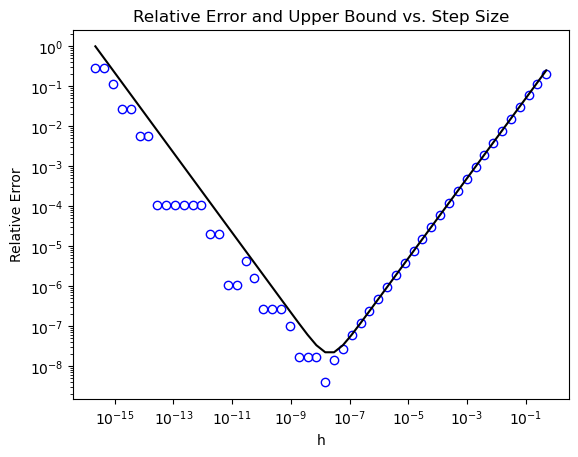

In [4]:
# Plot the error (r versus h) and upper bound (R versus h)

plt.loglog(h, r,'bo', markerfacecolor='none')
plt.loglog(h, R, 'k')
plt.xlabel('h')
plt.ylabel('Relative Error')
plt.title('Relative Error and Upper Bound vs. Step Size')

## Part 3

As h decreases from its largest value, the relative error r decreases until it reaches a minimum around the 10^-8 to 10^-7 range. After that point, the error begins to increase again as h becomes even smaller. This indicates that there is an optimal range of h where the backward difference approximation is the most accurate.

The upper bound R follows the same general trend as the relative error. It decreases at first, reaches a minimum, and then increases for very small values of h. Throughout the graph, R stays above the measured relative error r, which is consistent with it being an upper bound on the error.


## Part 4

This behavior makes sense because there are two different sources of error. When h is too large, the backward difference formula is not a close enough approximation of the derivative, so the approximation error is large. As h decreases, this error becomes smaller and the approximation becomes more accurate.

However, when h becomes extremely small, f(a) and f(a−h) are nearly equal. Subtracting these values causes significant-digit cancellation, and dividing the resulting roundoff error by an increasingly small \(h\) amplifies its effect on the derivative approximation. Therefore, the error is smallest at an intermediate value of h, where the approximation error and roundoff error are balanced.

## Part 5

Recall that R is defined as below:

$$
R = c_1 h + \frac{c_2}{h}
$$

To minimize, let the derivative of R equal 0:

$$
\frac{dR}{dh} = c_1 - \frac{c_2}{h^2} = 0
$$

The theoretical minimum of $R$ occurs at approximately $h=2.107\times10^{-8}$, which is consistent with the minimum observed in the numerical results and the graph.

Set $\frac{dR}{dh}=0$ and solve for $h$. We get $h$ to be $2.107*10^-8$

# Problem 3.4

## Part 1

In [5]:
# We must begin with V0 = ln(11/10)
import numpy as np

v0 = np.log(11/10)

# List of k
k_values = range(1, 21)

# Put Vk in here
vk = [v0]

# Initialize temp to hold v0
temp = v0

for num in k_values:
    temp = (1 / num) - 10 * temp
    vk.append(temp)

print("k | Vk | 1/(10(k+1)) | Vk/10^k")

for k, V in enumerate(vk):
    print(f"k={k:2d} : V={V:14.9f} : Bound={1/(10*(k+1)):14.9f} : V/10^k={(V / 10**k):14.9e}")

k | Vk | 1/(10(k+1)) | Vk/10^k
k= 0 : V=   0.095310180 : Bound=   0.100000000 : V/10^k=9.531017980e-02
k= 1 : V=   0.046898202 : Bound=   0.050000000 : V/10^k=4.689820196e-03
k= 2 : V=   0.031017980 : Bound=   0.033333333 : V/10^k=3.101798043e-04
k= 3 : V=   0.023153529 : Bound=   0.025000000 : V/10^k=2.315352901e-05
k= 4 : V=   0.018464710 : Bound=   0.020000000 : V/10^k=1.846470992e-06
k= 5 : V=   0.015352901 : Bound=   0.016666667 : V/10^k=1.535290084e-07
k= 6 : V=   0.013137658 : Bound=   0.014285714 : V/10^k=1.313765827e-08
k= 7 : V=   0.011480560 : Bound=   0.012500000 : V/10^k=1.148056018e-09
k= 8 : V=   0.010194398 : Bound=   0.011111111 : V/10^k=1.019439825e-10
k= 9 : V=   0.009167129 : Bound=   0.010000000 : V/10^k=9.167128613e-12
k=10 : V=   0.008328714 : Bound=   0.009090909 : V/10^k=8.328713865e-13
k=11 : V=   0.007621952 : Bound=   0.008333333 : V/10^k=7.621952257e-14
k=12 : V=   0.007113811 : Bound=   0.007692308 : V/10^k=7.113810768e-15
k=13 : V=   0.005784969 : Bound= 

## Part 2

As k increases, the computed values decrease. Once the computed value reaches k=14, the computed value begins to increase and alternate in sign.

## Part 3

Let $\hat{V}_k$ represent the computed values with error. Let $e_k$ represent the error. We know from error propagation that error is added to the original, so:

$$
\hat{V_k} = V_k + e_k
$$
$$
e_k = \hat{V_k} - V_k
$$

Now we can plug in the equations representing $\hat{V}_k$ and $V_k$

$$
e_k=\hat{V}_k-V_k
$$

$$
=\left(\frac{1}{k}-10\hat{V}_{k-1}\right)-\left(\frac{1}{k}-10V_{k-1}\right)
$$

$$
=-10\left(\hat{V}_{k-1}-V_{k-1}\right)=-10e_{k-1}
$$

After some manipulation, you can write the error generally:

$$
e_1=-10e_0,\quad e_2=(-10)^2e_0,\quad e_3=(-10)^3e_0
$$

$$
\therefore\ e_k=(-10)^k e_0
$$

As k increases, the error is multiplied by −10 at every step. Thus, the sign of the error alternates while its magnitude increases by a factor of 10. As a result, the computed values eventually deviate significantly from the true values, causing them to violate the bounds established in Equation (3.45).

## Part 4

In [6]:
# Re-run the program for e=0.17, 0.0023, and 0.000036

e1 = 0.17
e2 = 0.0023
e3 = 0.000036

v0e1 = v0 + e1
v0e2 = v0 + e2
v0e3 = v0 + e3

# List of k
k = [i for i in range(1,21)]

# Put Vk in here
vke1 =[]

# Initialize temp
temp = v0e1

print(f"Vk when error={e1}\n\n")
for num in k:
    temp = (1 / num) - 10 * temp
    vke1.append(temp)

for k, V in enumerate(vke1, start=1):
    print(f"k={k:2d} : V={V:14.9f} : V/10^k={(V / 10**k):14.9e}")

# Put Vk in here
vke2 =[]

# Initialize temp
temp = v0e2

print(f"Vk when error={e2}\n\n")
for num in k_values:
    temp = (1 / num) - 10 * temp
    vke2.append(temp)

for k, V in enumerate(vke2, start=1):
    print(f"k={k:2d} : V={V:14.9f} : V/10^k={(V / 10**k):14.9e}")

# Put Vk in here
vke3 =[]

# Initialize temp
temp = v0e3

print(f"Vk when error={e3}\n\n")
for num in k_values:
    temp = (1 / num) - 10 * temp
    vke3.append(temp)

for k, V in enumerate(vke3, start=1):
    print(f"k={k:2d} : V={V:14.9f} : V/10^k={(V / 10**k):14.9e}")

Vk when error=0.17


k= 1 : V=  -1.653101798 : V/10^k=-1.653101798e-01
k= 2 : V=  17.031017980 : V/10^k=1.703101798e-01
k= 3 : V=-169.976846471 : V/10^k=-1.699768465e-01
k= 4 : V=1700.018464710 : V/10^k=1.700018465e-01
k= 5 : V=-16999.984647099 : V/10^k=-1.699998465e-01
k= 6 : V=170000.013137658 : V/10^k=1.700000131e-01
k= 7 : V=-1699999.988519439 : V/10^k=-1.699999989e-01
k= 8 : V=17000000.010194395 : V/10^k=1.700000001e-01
k= 9 : V=-169999999.990832835 : V/10^k=-1.700000000e-01
k=10 : V=1700000000.008328199 : V/10^k=1.700000000e-01
k=11 : V=-16999999999.992372513 : V/10^k=-1.700000000e-01
k=12 : V=170000000000.007080078 : V/10^k=1.700000000e-01
k=13 : V=-1699999999999.993896484 : V/10^k=-1.700000000e-01
k=14 : V=17000000000000.011718750 : V/10^k=1.700000000e-01
k=15 : V=-170000000000000.062500000 : V/10^k=-1.700000000e-01
k=16 : V=1700000000000000.500000000 : V/10^k=1.700000000e-01
k=17 : V=-17000000000000004.000000000 : V/10^k=-1.700000000e-01
k=18 : V=170000000000000032.000000000 :

When e=0.17, $|\frac{V_k}{10^k}|$ approaches 0.17
When e=0.0023, $|\frac{V_k}{10^k}|$ approaches 0.0023
When e=0.000036, $|\frac{V_k}{10^k}|$ approaches 0.000036